### Extracting the dataset and inspecting file availability/sizes

In [ ]:
import os
import zipfile

zip_path = '/content/Student folder.zip'
extract_dir = '/content/student_folder'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extracted files:")
for root, dirs, files in os.walk(extract_dir):
    for file in files:
        fp = os.path.join(root, file)
        size_mb = os.path.getsize(fp) / (1024 * 1024)
        print(f"{os.path.relpath(fp, extract_dir)} - {size_mb:.2f} MB")

Extracted files:
Student folder/.DS_Store - 0.01 MB
Student folder/student_test/00000009/00000009.track - 0.03 MB
Student folder/student_test/00000009/00000009.arcs - 0.12 MB
Student folder/student_test/00000009/00000009.route - 0.00 MB
Student folder/student_test/00000009/00000009.nodes - 0.13 MB
Student folder/student_test/00000056/00000056.route - 0.01 MB
Student folder/student_test/00000056/00000056.arcs - 0.27 MB
Student folder/student_test/00000056/00000056.nodes - 0.30 MB
Student folder/student_test/00000056/00000056.track - 0.13 MB
Student folder/student_test/00000007/00000007.route - 0.00 MB
Student folder/student_test/00000007/00000007.nodes - 0.04 MB
Student folder/student_test/00000007/00000007.arcs - 0.04 MB
Student folder/student_test/00000007/00000007.track - 0.04 MB
Student folder/student_test/00000052/00000052.arcs - 0.03 MB
Student folder/student_test/00000052/00000052.track - 0.01 MB
Student folder/student_test/00000052/00000052.route - 0.00 MB
Student folder/student

### Geographic Analysis (Entirety of the Train Dataset)

We will now run a clean analysis strictly on the **entire `train` partition** to extract:
1. Overall coordinate bounding box ranges (latitude and longitude extremes).
2. Geographic bounding box for each trip in the train dataset.
3. Density plot and scatter plot of starting vs. ending coordinates.

=== Overall Geographic Coverage (Train Dataset) ===
Longitude Range: [-100.418538, 137.237029]
Latitude Range:  [-34.640291, 61.267258]

=== Geographic Bounding Box per Train Trip (All Rows) ===


,trip_id,min_lon,max_lon,min_lat,max_lat
0,00000019,6.893696,7.382203,52.105923,52.223884
1,00000079,37.520765,37.641395,55.756688,55.803325
2,00000048,-1.859966,-1.833160,52.957079,52.974960
3,00000054,4.847402,4.974103,52.286164,52.424972
4,00000012,44.044515,44.389906,36.175914,36.263587
5,00000020,24.354626,24.595931,52.560000,52.764968
6,00000037,137.197657,137.237029,36.667355,36.695646
7,00000089,30.301312,30.358962,59.989342,60.026200
8,00000038,27.449035,27.528154,53.843719,53.913008
9,00000096,-95.869374,-95.331981,36.137525,36.262757


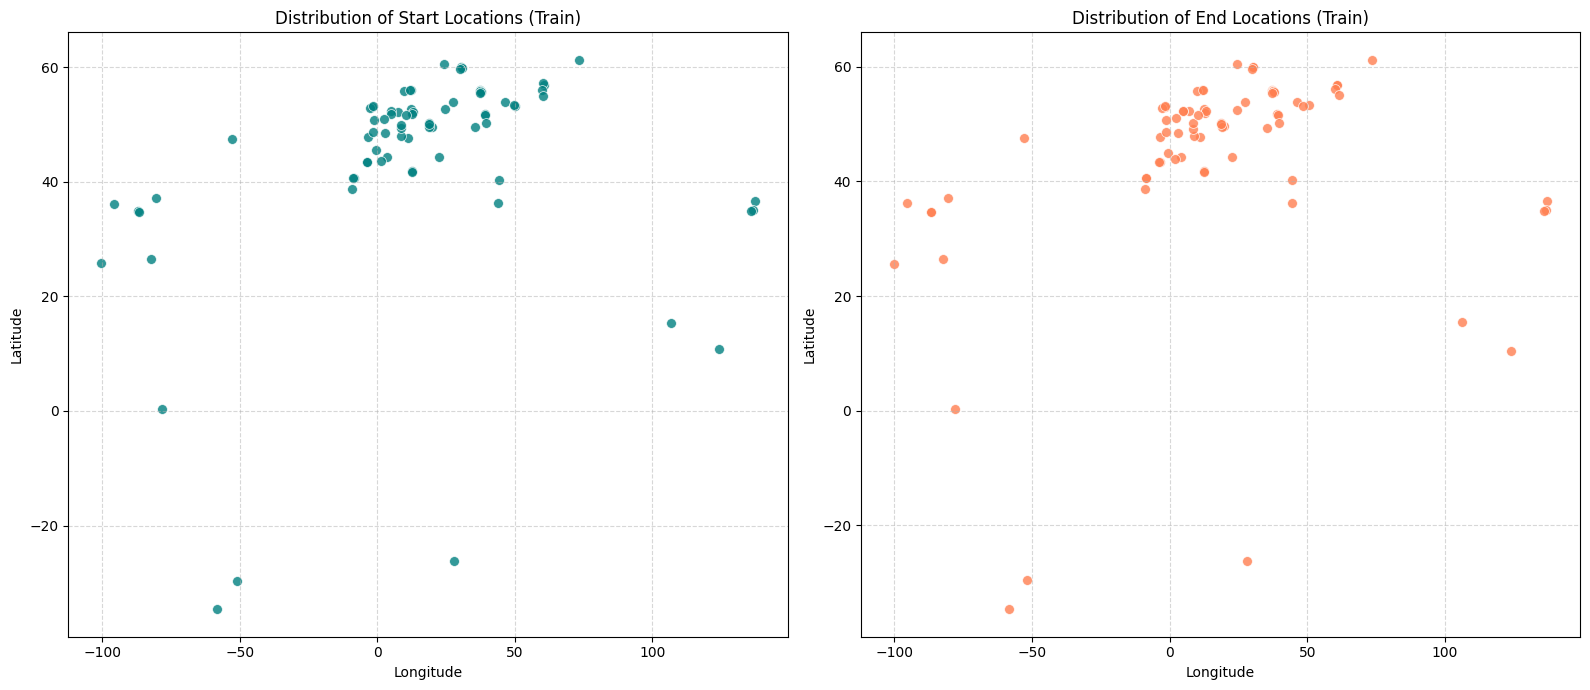

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Filter exclusively for the train partition
df_refined_train = df_refined[df_refined['partition'] == 'train']
df_endpoints_train = df_endpoints[df_endpoints['partition'] == 'train']

# 1. Extreme limits
train_min_lon = df_refined_train['min_lon'].min()
train_max_lon = df_refined_train['max_lon'].max()
train_min_lat = df_refined_train['min_lat'].min()
train_max_lat = df_refined_train['max_lat'].max()

print("=== Overall Geographic Coverage (Train Dataset) ===")
print(f"Longitude Range: [{train_min_lon:.6f}, {train_max_lon:.6f}]")
print(f"Latitude Range:  [{train_min_lat:.6f}, {train_max_lat:.6f}]")

# 2. Bounding boxes for all train trips
print("\n=== Geographic Bounding Box per Train Trip (All Rows) ===")
pd.set_option('display.max_rows', None)  # Ensure the user can inspect all of them
display(df_refined_train[['trip_id', 'min_lon', 'max_lon', 'min_lat', 'max_lat']].reset_index(drop=True))
pd.reset_option('display.max_rows')

# 3. Distribution of starting and ending locations
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.scatterplot(data=df_endpoints_train, x='start_lon', y='start_lat', color='teal', ax=axes[0], alpha=0.8, s=50)
axes[0].set_title('Distribution of Start Locations (Train)')
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.5)

sns.scatterplot(data=df_endpoints_train, x='end_lon', y='end_lat', color='coral', ax=axes[1], alpha=0.8, s=50)
axes[1].set_title('Distribution of End Locations (Train)')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Trajectory Exploration (Train Dataset)
We will explore:
- Raw GPS trajectories.
- A comparison of short, medium, and long trips (categorized by number of GPS points).
- Visualizations of trajectory shapes and identification of unusual flight/travel patterns.

--- Distribution of Trip Length Categories in Train Partition ---
trip_length_category
Long      27
Short     27
Medium    26
Name: count, dtype: int64


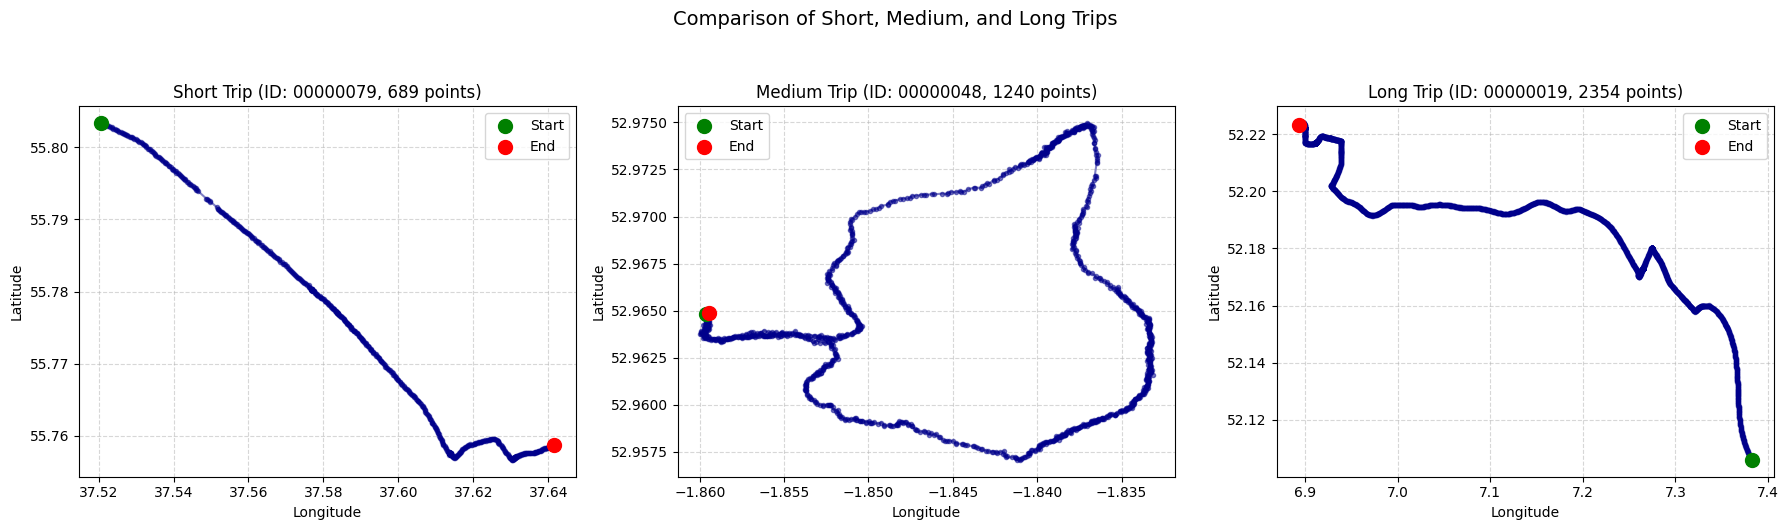

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Filter train partition
df_refined_train = df_refined[df_refined['partition'] == 'train'].copy()

# Categorize trip lengths based on quantiles of GPS observations
q33 = df_refined_train['gps_observations'].quantile(0.33)
q66 = df_refined_train['gps_observations'].quantile(0.66)

def categorize_length(obs):
    if obs <= q33:
        return 'Short'
    elif obs <= q66:
        return 'Medium'
    else:
        return 'Long'

df_refined_train['trip_length_category'] = df_refined_train['gps_observations'].apply(categorize_length)
print("--- Distribution of Trip Length Categories in Train Partition ---")
print(df_refined_train['trip_length_category'].value_counts())

# Helper function to load and plot a single trajectory
def load_track(trip_id, partition='train'):
    track_path = f"/content/student_folder/Student folder/{partition}/{trip_id}/{trip_id}.track"
    return pd.read_csv(track_path, sep=None, names=['lon', 'lat', 'time'], engine='python', comment='#')

# Pick representative samples
samples = {}
for cat in ['Short', 'Medium', 'Long']:
    subset = df_refined_train[df_refined_train['trip_length_category'] == cat]
    if not subset.empty:
        samples[cat] = subset.iloc[0]['trip_id']

# Plot the comparative trajectories
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (cat, tid) in enumerate(samples.items()):
    df_track = load_track(tid)
    axes[i].plot(df_track['lon'], df_track['lat'], marker='.', alpha=0.5, color='darkblue')
    axes[i].scatter(df_track['lon'].iloc[0], df_track['lat'].iloc[0], color='green', s=100, label='Start', zorder=5)
    axes[i].scatter(df_track['lon'].iloc[-1], df_track['lat'].iloc[-1], color='red', s=100, label='End', zorder=5)
    axes[i].set_title(f"{cat} Trip (ID: {tid}, {len(df_track)} points)")
    axes[i].set_xlabel('Longitude')
    axes[i].set_ylabel('Latitude')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend()

plt.suptitle('Comparison of Short, Medium, and Long Trips', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

Let's also look for unusual trajectory shapes, such as extreme self-intersections or circular patterns by plotting another set of trips.

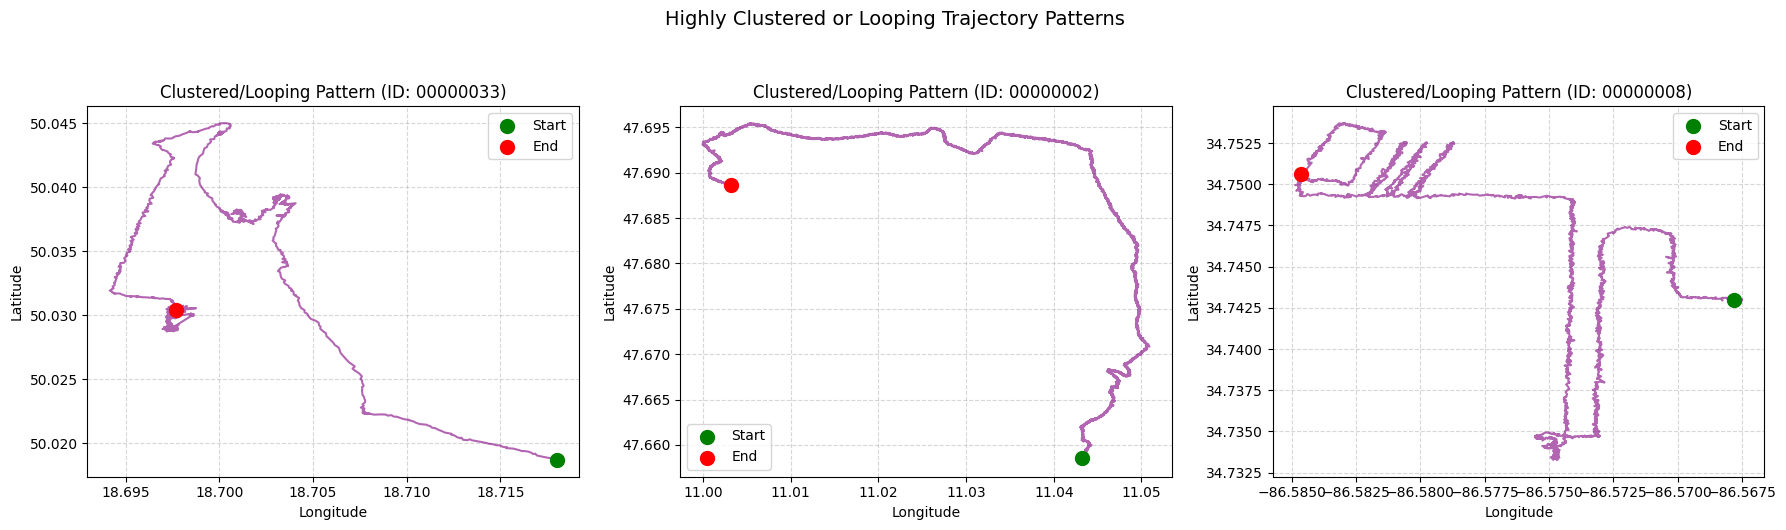

In [19]:
# Identify highly irregular trajectories (e.g. high observation count but tiny bounding boxes, showing loops)
df_refined_train['span_lon'] = df_refined_train['max_lon'] - df_refined_train['min_lon']
df_refined_train['span_lat'] = df_refined_train['max_lat'] - df_refined_train['min_lat']
df_refined_train['spatial_density'] = df_refined_train['gps_observations'] / (df_refined_train['span_lon'] + df_refined_train['span_lat'] + 1e-9)

# Sort to find the highest spatial density (lots of coordinates clustered together, suggesting circling/loops)
unusual_trips = df_refined_train.sort_values(by='spatial_density', ascending=False).head(3)['trip_id'].tolist()

# Plot some unusual trajectory patterns
fig, axes = plt.subplots(1, len(unusual_trips), figsize=(18, 5))
for i, tid in enumerate(unusual_trips):
    df_track = load_track(tid)
    axes[i].plot(df_track['lon'], df_track['lat'], color='purple', alpha=0.6)
    axes[i].scatter(df_track['lon'].iloc[0], df_track['lat'].iloc[0], color='green', s=100, label='Start', zorder=5)
    axes[i].scatter(df_track['lon'].iloc[-1], df_track['lat'].iloc[-1], color='red', s=100, label='End', zorder=5)
    axes[i].set_title(f"Clustered/Looping Pattern (ID: {tid})")
    axes[i].set_xlabel('Longitude')
    axes[i].set_ylabel('Latitude')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend()

plt.suptitle('Highly Clustered or Looping Trajectory Patterns', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

### Detailed GPS Trajectory Anomaly Detection

To identify potential outliers, GPS drift, and jagged coordinates, we will calculate several step-by-step metrics for the points in each track:
- **Instantaneous Velocity/Speed**: To detect sudden spatial jumps.
- **Heading Changes (Turn Angles)**: To detect back-and-forth zigzag patterns.
- **GPS Drift / Noise**: Point scatter during stationary or extremely slow sequences.

--- Anomaly Analysis for Trip 00000019 ---
Total Track Points: 2354
Sudden Jumps Detected (Speed > 50 m/s): 2
Zigzag Patterns Detected (Bearing Change > 150°): 109


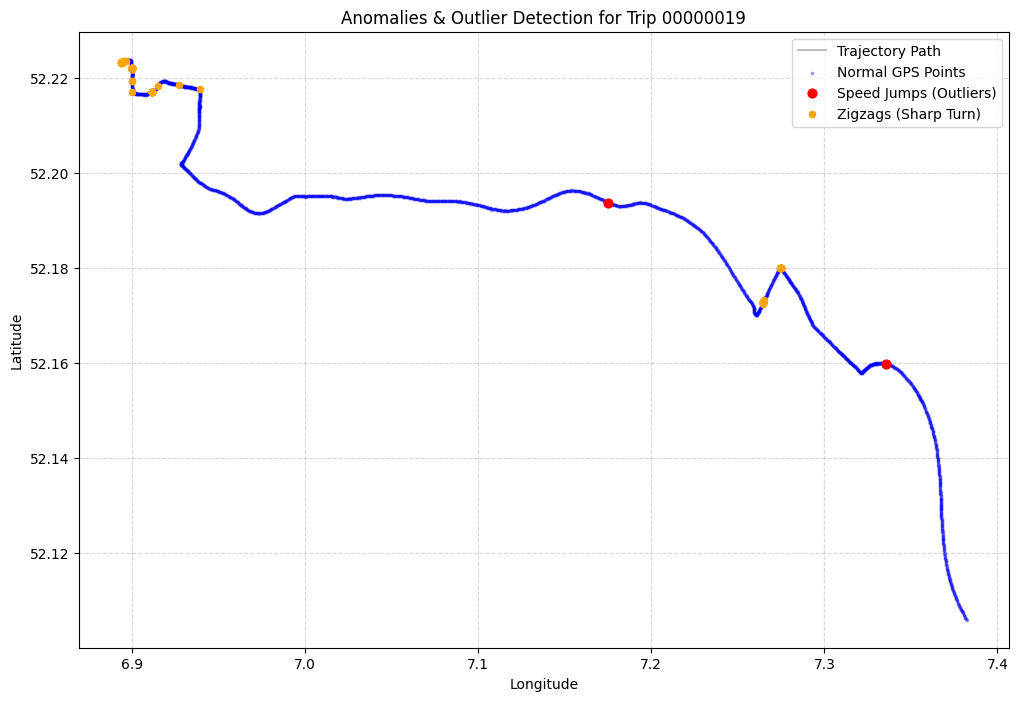

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Helper to calculate distance between two coordinates in meters
def haversine_distance(lon1, lat1, lon2, lat2):
    # Approximate Earth radius in meters
    R = 6371000.0

    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)

    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)

    a = np.sin(delta_phi / 2.0) ** 2 + \
        np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2.0) ** 2
    c = 2.0 * np.arctan2(np.sqrt(a), np.sqrt(1.0 - a))

    return R * c

# Analyze speed jumps and zigzags for a sample train trip
sample_trip_id = '00000019'
df_track = load_track(sample_trip_id)

# Calculate step distances, time gaps, speed, and bearing changes
df_track['prev_lon'] = df_track['lon'].shift(1)
df_track['prev_lat'] = df_track['lat'].shift(1)
df_track['prev_time'] = df_track['time'].shift(1)

df_track['distance_m'] = haversine_distance(
    df_track['lon'], df_track['lat'],
    df_track['prev_lon'], df_track['prev_lat']
)
df_track['time_diff_s'] = df_track['time'] - df_track['prev_time']
# Avoid division by zero
df_track['speed_m_s'] = df_track['distance_m'] / (df_track['time_diff_s'] + 1e-9)

# Calculate bearings to find zigzags (abrupt direction reversals of ~180 degrees)
def calculate_bearing(lon1, lat1, lon2, lat2):
    d_lon = np.radians(lon2 - lon1)
    y = np.sin(d_lon) * np.cos(np.radians(lat2))
    x = np.cos(np.radians(lat1)) * np.sin(np.radians(lat2)) - \
        np.sin(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.cos(d_lon)
    bearing = np.degrees(np.arctan2(y, x))
    return (bearing + 360) % 360

df_track['bearing'] = calculate_bearing(
    df_track['prev_lon'], df_track['prev_lat'],
    df_track['lon'], df_track['lat']
)
df_track['bearing_diff'] = np.abs(df_track['bearing'] - df_track['bearing'].shift(1))
df_track['bearing_diff'] = np.where(df_track['bearing_diff'] > 180, 360 - df_track['bearing_diff'], df_track['bearing_diff'])

# Identify anomalies
# 1. Sudden spatial jumps (speed > 50 m/s (~180 km/h) for non-flight tracks)
jump_anomalies = df_track[df_track['speed_m_s'] > 50]
# 2. Zigzags (bearing change > 150 degrees with a non-trivial movement of > 5 meters)
zigzag_anomalies = df_track[(df_track['bearing_diff'] > 150) & (df_track['distance_m'] > 5)]

print(f"--- Anomaly Analysis for Trip {sample_trip_id} ---")
print(f"Total Track Points: {len(df_track)}")
print(f"Sudden Jumps Detected (Speed > 50 m/s): {len(jump_anomalies)}")
print(f"Zigzag Patterns Detected (Bearing Change > 150°): {len(zigzag_anomalies)}")

# Visualize the trajectory with highlighted anomalies
plt.figure(figsize=(12, 8))
plt.plot(df_track['lon'], df_track['lat'], color='gray', alpha=0.5, label='Trajectory Path', zorder=1)
plt.scatter(df_track['lon'], df_track['lat'], color='blue', s=3, alpha=0.3, label='Normal GPS Points', zorder=2)

if not jump_anomalies.empty:
    plt.scatter(jump_anomalies['lon'], jump_anomalies['lat'], color='red', s=40, label='Speed Jumps (Outliers)', zorder=3)
if not zigzag_anomalies.empty:
    plt.scatter(zigzag_anomalies['lon'], zigzag_anomalies['lat'], color='orange', s=20, label='Zigzags (Sharp Turn)', zorder=4)

plt.title(f"Anomalies & Outlier Detection for Trip {sample_trip_id}")
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [21]:
import pandas as pd
import numpy as np

anomaly_records = []

for tid in df_refined_train['trip_id'].unique():
    try:
        df_track = load_track(tid)
        if len(df_track) < 3:
            continue

        df_track['prev_lon'] = df_track['lon'].shift(1)
        df_track['prev_lat'] = df_track['lat'].shift(1)
        df_track['prev_time'] = df_track['time'].shift(1)

        # Step metrics
        df_track['distance_m'] = haversine_distance(
            df_track['lon'], df_track['lat'],
            df_track['prev_lon'], df_track['prev_lat']
        )
        df_track['time_diff_s'] = df_track['time'] - df_track['prev_time']
        df_track['speed_m_s'] = df_track['distance_m'] / (df_track['time_diff_s'] + 1e-9)

        # Bearings
        df_track['bearing'] = calculate_bearing(
            df_track['prev_lon'], df_track['prev_lat'],
            df_track['lon'], df_track['lat']
        )
        df_track['bearing_diff'] = np.abs(df_track['bearing'] - df_track['bearing'].shift(1))
        df_track['bearing_diff'] = np.where(df_track['bearing_diff'] > 180, 360 - df_track['bearing_diff'], df_track['bearing_diff'])

        # Detection thresholds
        jumps = len(df_track[df_track['speed_m_s'] > 50])
        zigzags = len(df_track[(df_track['bearing_diff'] > 150) & (df_track['distance_m'] > 5)])

        anomaly_records.append({
            'trip_id': tid,
            'points': len(df_track),
            'jumps': jumps,
            'zigzags': zigzags,
            'max_speed': df_track['speed_m_s'].max()
        })
    except Exception as e:
        pass

df_anomalies_all = pd.DataFrame(anomaly_records)
print("=== Summary of Anomalies across all Train Trips ===")
print(f"Total Train Trips analyzed: {len(df_anomalies_all)}")
print(f"Total Sudden Jumps (>50m/s) across whole train set: {df_anomalies_all['jumps'].sum()}")
print(f"Total Zigzag Anomalies (>150 degrees) across whole train set: {df_anomalies_all['zigzags'].sum()}")

print("\n=== Top 5 Most Noisy Trips (by absolute Zigzag count) ===")
display(df_anomalies_all.sort_values(by='zigzags', ascending=False).head(5))

=== Summary of Anomalies across all Train Trips ===
Total Train Trips analyzed: 80
Total Sudden Jumps (>50m/s) across whole train set: 1524
Total Zigzag Anomalies (>150 degrees) across whole train set: 22494

=== Top 5 Most Noisy Trips (by absolute Zigzag count) ===


,trip_id,points,jumps,zigzags,max_speed
3,00000054,19313,1,4491,50.562467
78,00000021,15783,0,2940,45.949671
13,00000084,16031,0,2662,49.225021
22,00000002,7243,0,1837,37.274301
60,00000033,5844,3,1384,141.950913


=== Summary Statistics for Distance Metrics (Train Dataset) ===


,actual_distance_km,straight_line_distance_km,detour_ratio
count,80.000000,80.000000,80.000000
mean,37.230137,17.305642,401.778397
std,34.501831,20.443439,2972.330186
min,6.334162,0.001459,1.098361
25%,12.777440,3.649150,1.459750
50%,24.065686,8.181687,1.986540
75%,48.714677,24.589800,5.789256
max,169.253772,75.370838,26580.937045



=== Top 5 Most Winding/Indirect Trips (by detour ratio) ===


,trip_id,points,actual_distance_km,straight_line_distance_km,detour_ratio
55,00000081,3224,38.791186,0.001459,26580.937045
2,00000048,1240,11.930453,0.010405,1146.564710
35,00000095,1551,16.094291,0.017286,931.058792
69,00000069,2067,25.742200,0.028841,892.556285
53,00000046,1401,12.027436,0.015002,801.743610


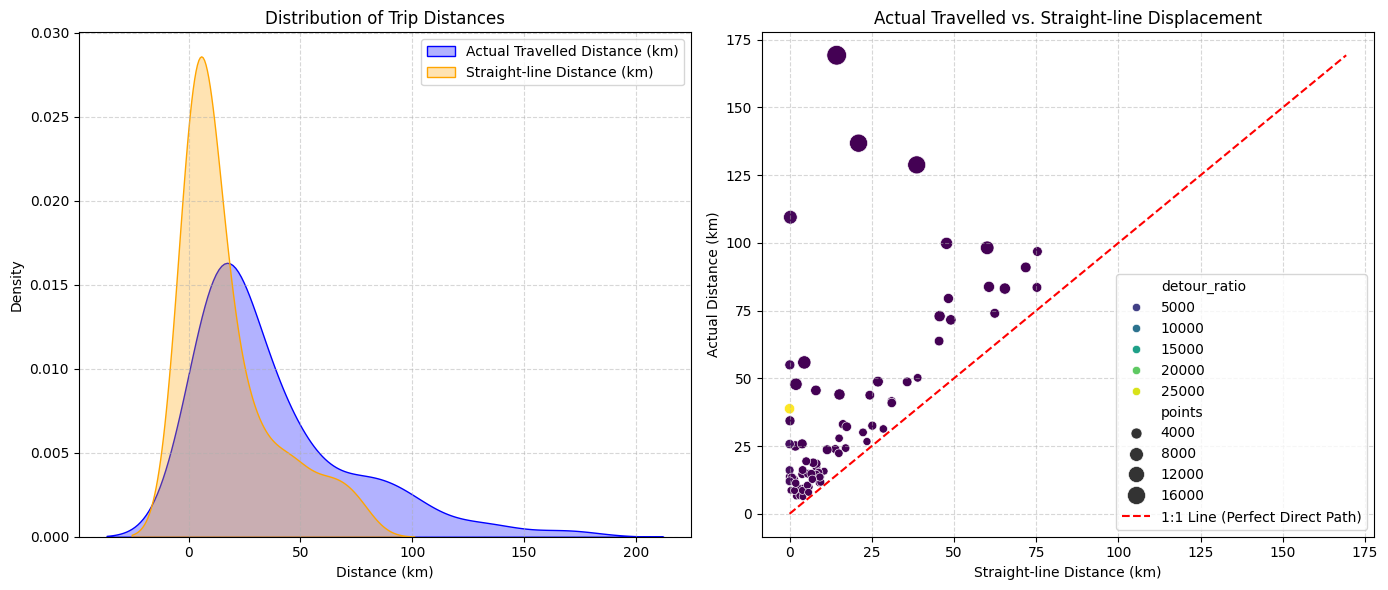

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

distance_records = []

for tid in df_refined_train['trip_id'].unique():
    try:
        df_track = load_track(tid)
        if len(df_track) < 2:
            continue

        # 1. Actual Travelled Distance (sum of all consecutive step distances)
        df_track['prev_lon'] = df_track['lon'].shift(1)
        df_track['prev_lat'] = df_track['lat'].shift(1)
        df_track['step_distance_m'] = haversine_distance(
            df_track['lon'], df_track['lat'],
            df_track['prev_lon'], df_track['prev_lat']
        )
        total_travelled_m = df_track['step_distance_m'].sum()

        # 2. Straight-line displacement distance (Start to End)
        start_lon, start_lat = df_track['lon'].iloc[0], df_track['lat'].iloc[0]
        end_lon, end_lat = df_track['lon'].iloc[-1], df_track['lat'].iloc[-1]
        straight_line_m = haversine_distance(start_lon, start_lat, end_lon, end_lat)

        # 3. Detour / Tortuosity Ratio (actual / straight-line)
        detour_ratio = total_travelled_m / (straight_line_m + 1e-9)

        distance_records.append({
            'trip_id': tid,
            'points': len(df_track),
            'actual_distance_km': total_travelled_m / 1000.0,
            'straight_line_distance_km': straight_line_m / 1000.0,
            'detour_ratio': detour_ratio
        })
    except Exception as e:
        pass

df_distances = pd.DataFrame(distance_records)

print("=== Summary Statistics for Distance Metrics (Train Dataset) ===")
display(df_distances[['actual_distance_km', 'straight_line_distance_km', 'detour_ratio']].describe())

# Find top 5 trips with highest detours / winding indices
print("\n=== Top 5 Most Winding/Indirect Trips (by detour ratio) ===")
display(df_distances.sort_values(by='detour_ratio', ascending=False).head(5))

# Visualization of Travelled vs. Straight-Line Distances
plt.figure(figsize=(14, 6))

# Plot 1: Distributions comparison
plt.subplot(1, 2, 1)
sns.kdeplot(df_distances['actual_distance_km'], label='Actual Travelled Distance (km)', color='blue', fill=True, alpha=0.3)
sns.kdeplot(df_distances['straight_line_distance_km'], label='Straight-line Distance (km)', color='orange', fill=True, alpha=0.3)
plt.title('Distribution of Trip Distances')
plt.xlabel('Distance (km)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Plot 2: Scatter correlation
plt.subplot(1, 2, 2)
sns.scatterplot(data=df_distances, x='straight_line_distance_km', y='actual_distance_km', hue='detour_ratio', palette='viridis', size='points', sizes=(30, 200))
plt.plot([0, df_distances['actual_distance_km'].max()], [0, df_distances['actual_distance_km'].max()], color='red', linestyle='--', label='1:1 Line (Perfect Direct Path)')
plt.title('Actual Travelled vs. Straight-line Displacement')
plt.xlabel('Straight-line Distance (km)')
plt.ylabel('Actual Distance (km)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()